In [1]:
%pip install scikit-learn -q


[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import re
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel, PeftConfig

print("✅ All libraries imported successfully!")

/home/jovyan/Works/MSc_Thesis/mh_venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ All libraries imported successfully!


In [3]:
from datasets import load_from_disk
dataset_based_path = "/home/jovyan/Works/MSc_Thesis/dataset"
dataset = load_from_disk(f"{dataset_based_path}/mh-function-calling-dataset-hf-v3")

In [4]:
test_dataset = dataset["test"]
# test_dataset = test_dataset.select(range(100))

In [5]:
# Load trained model
peft_model_id = "/home/jovyan/Works/MSc_Thesis/mh_function_calling/model_training/finetuned_models/llama3.2_3b_mh_function_calling_v6"

print("Loading trained model...")

# Load PEFT config
config = PeftConfig.from_pretrained(peft_model_id)
print(f"Base model: {config.base_model_name_or_path}")

# Load base model
model = AutoModelForCausalLM.from_pretrained(
    config.base_model_name_or_path,
    device_map={"": 0},
    torch_dtype=torch.bfloat16
)

# Load tokenizer (with special tokens)
tokenizer = AutoTokenizer.from_pretrained(peft_model_id)
print(f"Tokenizer vocab size: {len(tokenizer)}")

# Resize embeddings
model.resize_token_embeddings(len(tokenizer))

# Load adapter weights
model = PeftModel.from_pretrained(model, peft_model_id)
model.to(torch.bfloat16)
model.eval()

print("✅ Model loaded successfully!")

Loading trained model...
Base model: meta-llama/Llama-3.2-3B-Instruct


Loading checkpoint shards: 100%|██████████| 2/2 [00:00<00:00,  2.01it/s]
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Tokenizer vocab size: 128260


/home/jovyan/Works/MSc_Thesis/mh_venv/lib/python3.12/site-packages/peft/tuners/tuners_utils.py:574: UserWarning: Model with `tie_word_embeddings=True` and the tied_target_modules=['model.embed_tokens', 'lm_head'] are part of the adapter. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. See for example https://github.com/huggingface/peft/issues/2018.
  warnings.warn(


✅ Model loaded successfully!


In [6]:
def extract_function_from_response(response):
    """Extract function name and parameters from model response"""
    try:
        # Find content between <function> and </function> tags
        function_match = re.search(r'<function>\s*(.*?)\s*</function>', response, re.DOTALL)
        
        if function_match:
            function_content = function_match.group(1).strip()
            
            # Parse JSON
            function_data = json.loads(function_content)
            
            return {
                'function_name': function_data.get('name', ''),
                'parameters': function_data.get('parameters', {}),
                'raw_function': function_content,
                'extracted_successfully': True
            }
        else:
            return {
                'function_name': '',
                'parameters': {},
                'raw_function': '',
                'extracted_successfully': False
            }
            
    except (json.JSONDecodeError, KeyError, AttributeError) as e:
        return {
            'function_name': '',
            'parameters': {},
            'raw_function': response,
            'extracted_successfully': False,
            'error': str(e)
        }

def compare_parameters(predicted_params, ground_truth_params):
    """Compare predicted parameters with ground truth"""
    if not isinstance(predicted_params, dict) or not isinstance(ground_truth_params, dict):
        return False
    
    # Check if all ground truth parameters are present and correct
    for key, value in ground_truth_params.items():
        if key not in predicted_params:
            return False
        if predicted_params[key] != value:
            return False
    
    return True

print("✅ Utility functions defined!")

✅ Utility functions defined!


In [7]:
def test_model_on_sample(patient_id, query, max_length=1024):
    """Test model on a single sample"""
    messages = [
        {
            "role": "system",
            "content": "You are a helpful mental health assistant. When users ask for health data, use the available functions to retrieve the information. Think through your response before choosing a function. Use <think>your reasoning</think> tags to show your thought process, then use <function>json</function> tags to call the appropriate function."
        },
        {
            "role": "user",
            "content": f"Patient ID: {patient_id}\nQuery: {query}"
        }
    ]
    
    prompt = tokenizer.apply_chat_template(
        messages, 
        tokenize=False, 
        add_generation_prompt=True
    )
    
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    input_length = inputs['input_ids'].shape[1]
    
    with torch.no_grad():
        outputs = model.generate(
              **inputs,
            max_new_tokens=max_length,
            do_sample=True,
            temperature=0.1,              
            top_p=0.95,                 
            repetition_penalty=1.0,     
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    
    response_tokens = outputs[0][input_length:]
    response = tokenizer.decode(response_tokens, skip_special_tokens=False)
    response = response.replace(tokenizer.eos_token, "").strip()
    
    return response

print("✅ Model testing function ready!")

✅ Model testing function ready!


In [8]:
def parse_test_sample(text):
    """Parse test sample to extract components"""
    # Extract patient_id, query, and ground truth from formatted text
    patient_id_match = re.search(r'Patient ID: (\w+)', text)
    query_match = re.search(r'Pateint Query: (.*?)\n\n### Response:', text, re.DOTALL)
    ground_truth_match = re.search(r'### Response:\n(.*?)(?:<\|eot_id\||$)', text, re.DOTALL)
    
    if not all([patient_id_match, query_match, ground_truth_match]):
        return None
        
    return {
        'patient_id': patient_id_match.group(1),
        'query': query_match.group(1).strip(),
        'ground_truth_response': ground_truth_match.group(1).strip()
    }

# Test parsing on first sample
sample_data = parse_test_sample(test_dataset[1]['text'])
if sample_data:
    print("✅ Sample parsing successful!")
    print(f"Patient ID: {sample_data['patient_id']}")
    print(f"Query: {sample_data['query'][:100]}...")
    print(f"Ground truth: {sample_data['ground_truth_response'][:]}...")
else:
    print("❌ Failed to parse sample")

✅ Sample parsing successful!
Patient ID: P_2180
Query: Something tells me I’m not as fit as I was during winter....
Ground truth: <think>
The user is metaphorically expressing concerns about reduced fitness, possibly related to VO2 max. We'll use get_vo2max_data to check recent fitness levels. No time frame is given, so we'll default to 7 days.
</think>

<function>
{
  "name": "get_vo2max_data",
  "parameters": {
    "patient_id": "P_2180",
    "num_days": 7
  }
}
</function>...


In [9]:
print("🧪 Starting comprehensive evaluation...")
results = []

for i, sample in enumerate(test_dataset):
    # Parse sample
    parsed = parse_test_sample(sample['text'])
    if not parsed:
        print(f"⚠️ Skipping sample {i}: Could not parse")
        continue
    
    patient_id = parsed['patient_id']
    query = parsed['query']
    ground_truth_response = parsed['ground_truth_response']
    
    # Get model prediction
    predicted_response = test_model_on_sample(patient_id, query)
    
    # Extract functions
    predicted_function = extract_function_from_response(predicted_response)
    ground_truth_function = extract_function_from_response(ground_truth_response)
    
    # Store results
    result = {
        'sample_id': i,
        'patient_id': patient_id,
        'query': query,
        'ground_truth_response': ground_truth_response,
        'predicted_response': predicted_response,
        'ground_truth_function_name': ground_truth_function['function_name'],
        'predicted_function_name': predicted_function['function_name'],
        'ground_truth_parameters': ground_truth_function['parameters'],
        'predicted_parameters': predicted_function['parameters'],
        'function_extracted': predicted_function['extracted_successfully'],
        'function_name_correct': predicted_function['function_name'] == ground_truth_function['function_name'],
        'parameters_correct': compare_parameters(
            predicted_function['parameters'], 
            ground_truth_function['parameters']
        )
    }
    print(result)
    results.append(result)
    
    if (i + 1) % 5 == 0:
        print(f"✅ Processed {i + 1}/{len(test_dataset)} samples...")

print(f"🎯 Evaluation complete! Processed {len(results)} samples")

🧪 Starting comprehensive evaluation...


{'sample_id': 0, 'patient_id': 'P_1022', 'query': "Since my therapist suggested 'sleep restriction' for insomnia, I'm exhausted but sleeping deeper. Is this the expected pattern?", 'ground_truth_response': '<think>\nSleep restriction initially increases sleep drive. Reviewing 14 days of implementation will track the trajectory of sleep consolidation improvements.\n</think>\n\n<function>\n{\n  "name": "get_sleep_data",\n  "parameters": {\n    "patient_id": "P_1022",\n    "num_days": 14\n  }\n}\n</function>', 'predicted_response': '<think>\nRequest for sleep architecture analysis following therapeutic intervention. Comparing 7 nights pre- and post-suggestion will quantify changes in sleep efficiency and restorative sleep.\n</think>\n\n<function>\n{\n  "name": "get_sleep_data",\n  "parameters": {\n    "patient_id": "P_1022",\n    "num_days": 7\n  }\n}\n</function>', 'ground_truth_function_name': 'get_sleep_data', 'predicted_function_name': 'get_sleep_data', 'ground_truth_parameters': {'pa

In [10]:
# Function Name Metrics
y_true_functions = [r['ground_truth_function_name'] for r in results]
y_pred_functions = [r['predicted_function_name'] for r in results]

function_accuracy = accuracy_score(y_true_functions, y_pred_functions)

# Get unique function names
unique_functions = list(set(y_true_functions + y_pred_functions))

function_precision = precision_score(y_true_functions, y_pred_functions, 
                                   labels=unique_functions, average='weighted', zero_division=0)
function_recall = recall_score(y_true_functions, y_pred_functions, 
                             labels=unique_functions, average='weighted', zero_division=0)
function_f1 = f1_score(y_true_functions, y_pred_functions, 
                      labels=unique_functions, average='weighted', zero_division=0)

# Parameter Metrics
parameter_accuracy = sum(r['parameters_correct'] for r in results) / len(results)

# Overall Success Rate
overall_success = sum(r['function_name_correct'] and r['parameters_correct'] 
                     for r in results) / len(results)

# Extraction Success Rate
extraction_success = sum(r['function_extracted'] for r in results) / len(results)

print("📊 METRICS CALCULATED!")

📊 METRICS CALCULATED!


In [11]:
print("="*80)
print("🎯 COMPREHENSIVE FUNCTION CALLING EVALUATION REPORT")
print("="*80)

print(f"\n📊 OVERALL PERFORMANCE:")
print(f"   Total Samples Evaluated: {len(results)}")
print(f"   Function Extraction Success: {extraction_success:.3f}")
print(f"   Complete Success Rate (Name + Params): {overall_success:.3f}")

print(f"\n🎯 FUNCTION NAME METRICS:")
print(f"   Accuracy:  {function_accuracy:.3f}")
print(f"   Precision: {function_precision:.3f}")
print(f"   Recall:    {function_recall:.3f}")
print(f"   F1-Score:  {function_f1:.3f}")

print(f"\n⚙️ PARAMETER METRICS:")
print(f"   Parameter Accuracy: {parameter_accuracy:.3f}")

# Function-wise breakdown
function_breakdown = defaultdict(lambda: {'correct': 0, 'total': 0})
for result in results:
    func_name = result['ground_truth_function_name']
    function_breakdown[func_name]['total'] += 1
    if result['function_name_correct']:
        function_breakdown[func_name]['correct'] += 1

print(f"\n📈 FUNCTION-WISE BREAKDOWN:")
for func_name, stats in function_breakdown.items():
    accuracy = stats['correct'] / stats['total'] if stats['total'] > 0 else 0
    print(f"   {func_name}: {accuracy:.3f} ({stats['correct']}/{stats['total']})")

print("="*80)

🎯 COMPREHENSIVE FUNCTION CALLING EVALUATION REPORT

📊 OVERALL PERFORMANCE:
   Total Samples Evaluated: 765
   Function Extraction Success: 0.635
   Complete Success Rate (Name + Params): 0.375

🎯 FUNCTION NAME METRICS:
   Accuracy:  0.505
   Precision: 0.797
   Recall:    0.505
   F1-Score:  0.613

⚙️ PARAMETER METRICS:
   Parameter Accuracy: 0.478

📈 FUNCTION-WISE BREAKDOWN:
   get_sleep_data: 0.526 (20/38)
   get_vo2max_data: 0.372 (16/43)
   get_blood_glucose_data: 0.515 (17/33)
   get_distance_data: 0.605 (26/43)
   get_speed_data: 0.469 (15/32)
   get_stress_data: 0.341 (14/41)
   get_calories_burned_data: 0.233 (10/43)
   get_body_fat_data: 0.419 (18/43)
   get_heart_rate_data: 0.683 (28/41)
   get_steps_data: 0.444 (20/45)
   get_bmr_data: 0.405 (15/37)
   get_body_temp_data: 0.628 (27/43)
   get_blood_pressure_data: 0.529 (18/34)
   get_nutrition_data: 0.643 (27/42)
   get_exercise_session_data: 0.333 (12/36)
   get_height_data: 0.588 (20/34)
   get_oxygen_saturation_data: 0.51

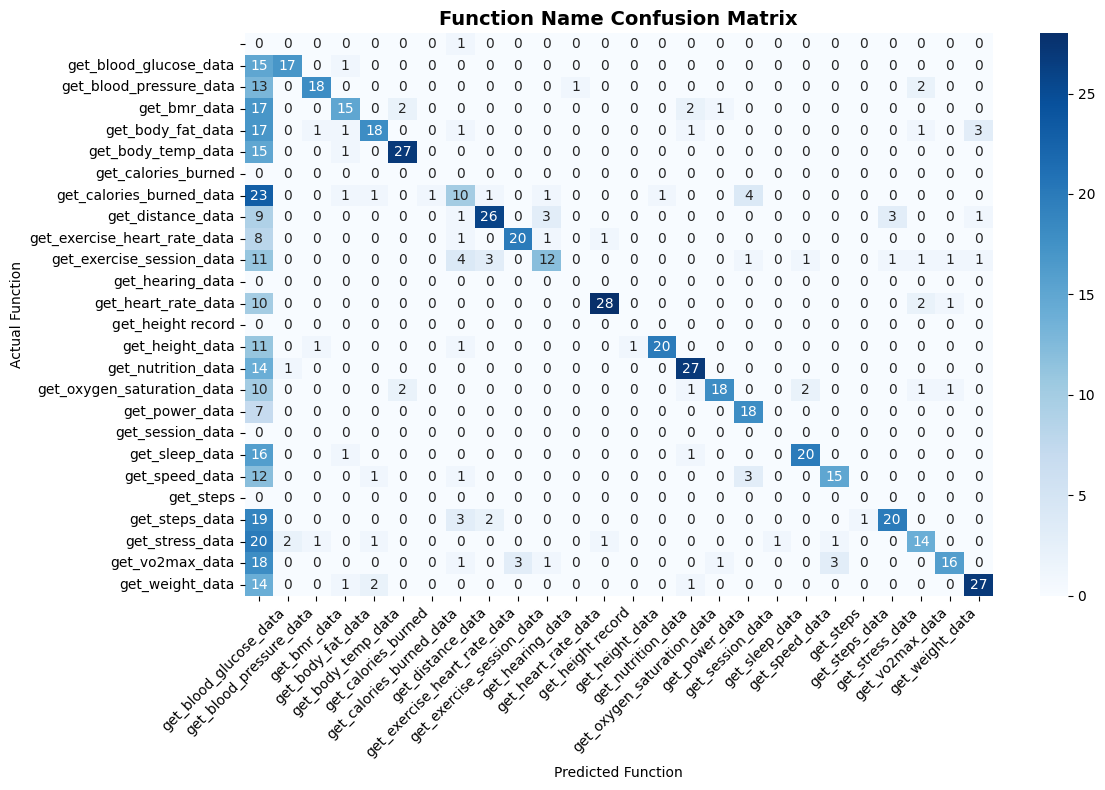

🎨 Confusion matrix plotted for 26 function types


In [12]:
# Plot confusion matrix
unique_functions = sorted(list(set(y_true_functions + y_pred_functions)))
cm_functions = confusion_matrix(y_true_functions, y_pred_functions, labels=unique_functions)

plt.figure(figsize=(12, 8))
sns.heatmap(cm_functions, annot=True, fmt='d', cmap='Blues',
            xticklabels=unique_functions, yticklabels=unique_functions)
plt.title('Function Name Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Function')
plt.ylabel('Actual Function')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"🎨 Confusion matrix plotted for {len(unique_functions)} function types")

In [13]:
# Analyze some specific examples
print("🔍 SAMPLE ANALYSIS:")
print("="*60)

# Show a few successful predictions
successful_samples = [r for r in results if r['function_name_correct'] and r['parameters_correct']]
if successful_samples:
    sample = successful_samples[0]
    print("✅ SUCCESSFUL PREDICTION EXAMPLE:")
    print(f"Query: {sample['query']}")
    print(f"Predicted Function: {sample['predicted_function_name']}")
    print(f"Predicted Parameters: {sample['predicted_parameters']}")
    print()

# Show a failed prediction
failed_samples = [r for r in results if not (r['function_name_correct'] and r['parameters_correct'])]
if failed_samples:
    sample = failed_samples[0]
    print("❌ FAILED PREDICTION EXAMPLE:")
    print(f"Query: {sample['query']}")
    print(f"Expected Function: {sample['ground_truth_function_name']}")
    print(f"Predicted Function: {sample['predicted_function_name']}")
    print(f"Expected Parameters: {sample['ground_truth_parameters']}")
    print(f"Predicted Parameters: {sample['predicted_parameters']}")

print("="*60)

🔍 SAMPLE ANALYSIS:
✅ SUCCESSFUL PREDICTION EXAMPLE:
Query: How’s my blood sugar been over the last 12 days with all this travel?
Predicted Function: get_blood_glucose_data
Predicted Parameters: {'patient_id': 'P_4024', 'num_days': 12}

❌ FAILED PREDICTION EXAMPLE:
Query: Since my therapist suggested 'sleep restriction' for insomnia, I'm exhausted but sleeping deeper. Is this the expected pattern?
Expected Function: get_sleep_data
Predicted Function: get_sleep_data
Expected Parameters: {'patient_id': 'P_1022', 'num_days': 14}
Predicted Parameters: {'patient_id': 'P_1022', 'num_days': 7}


In [14]:
print("🔍 MEMORIZATION DETECTION ANALYSIS")
print("="*60)

# 1. Check for exact response matching (strong memorization indicator)
exact_matches = 0
for result in results:
    # Remove whitespace and compare
    pred_clean = result['predicted_response'].strip().replace('\n', ' ').replace(' ', '')
    truth_clean = result['ground_truth_response'].strip().replace('\n', ' ').replace(' ', '')
    if pred_clean == truth_clean:
        exact_matches += 1

print(f"📋 Exact Response Matches: {exact_matches}/{len(results)} ({exact_matches/len(results)*100:.1f}%)")

# 2. Check reasoning diversity in <think> tags
think_patterns = set()
for result in results:
    think_match = re.search(r'<think>(.*?)</think>', result['predicted_response'], re.DOTALL)
    if think_match:
        think_content = think_match.group(1).strip()
        # Get first 50 chars as pattern
        pattern = think_content[:50] if len(think_content) > 50 else think_content
        think_patterns.add(pattern)

print(f"🧠 Unique Reasoning Patterns: {len(think_patterns)} patterns found")
print(f"📊 Reasoning Diversity: {len(think_patterns)/len(results)*100:.1f}% unique per sample")

# 3. Check patient ID distribution
patient_ids = [r['patient_id'] for r in results]
unique_patients = set(patient_ids)
print(f"👥 Unique Patients in Test: {len(unique_patients)}")
print(f"📈 Patient ID Distribution: {len(patient_ids)//len(unique_patients):.1f} samples per patient avg")

if exact_matches > len(results) * 0.8:  # If >80% exact matches
    print("\n⚠️  HIGH MEMORIZATION RISK DETECTED!")
else:
    print(f"\n✅ Memorization Risk: LOW ({exact_matches/len(results)*100:.1f}% exact matches)")

🔍 MEMORIZATION DETECTION ANALYSIS
📋 Exact Response Matches: 1/765 (0.1%)
🧠 Unique Reasoning Patterns: 668 patterns found
📊 Reasoning Diversity: 87.3% unique per sample
👥 Unique Patients in Test: 765
📈 Patient ID Distribution: 1.0 samples per patient avg

✅ Memorization Risk: LOW (0.1% exact matches)


In [15]:
print("\n🧪 NOVEL QUERY TESTING (Zero-shot generalization)")
print("="*60)

# Test with queries NOT in training format
novel_queries = [
    ("UID_NOVEL", "Could you please retrieve my sleeping pattern information for the previous week?"),
    ("UID_TEST", "I want to see how many steps I walked in the last 5 days"),
    ("UID_NEW", "Show me my heart rate measurements from the past 3 days"),
    ("UID_999", "Get my stress level data for the last 2 weeks"),
    ("UID_888", "I need my calorie burn information for 10 days")
]

novel_results = []
for patient_id, query in novel_queries:
    response = test_model_on_sample(patient_id, query)
    extracted = extract_function_from_response(response)
    
    novel_results.append({
        'query': query,
        'response': response,
        'extracted_function': extracted['function_name'],
        'extracted_params': extracted['parameters'],
        'extraction_success': extracted['extracted_successfully']
    })
    
    print(f"Query: {query}")
    print(f"Function: {extracted['function_name']}")
    print(f"Params: {extracted['parameters']}")
    print(f"Success: {extracted['extracted_successfully']}")
    print("-" * 40)

novel_success_rate = sum(1 for r in novel_results if r['extraction_success']) / len(novel_results)
print(f"\n🎯 Novel Query Success Rate: {novel_success_rate:.2f}")


🧪 NOVEL QUERY TESTING (Zero-shot generalization)


Query: Could you please retrieve my sleeping pattern information for the previous week?
Function: get_sleep_data
Params: {'patient_id': 'UID_NOVEL', 'num_days': 7}
Success: True
----------------------------------------
Query: I want to see how many steps I walked in the last 5 days
Function: get_steps_data
Params: {'patient_id': 'UID_TEST', 'num_days': 5}
Success: True
----------------------------------------
Query: Show me my heart rate measurements from the past 3 days
Function: get_heart_rate_data
Params: {'patient_id': 'UID_NEW', 'num_days': 3}
Success: True
----------------------------------------
Query: Get my stress level data for the last 2 weeks
Function: get_stress_data
Params: {'patient_id': 'UID_999', 'num_days': 14}
Success: True
----------------------------------------
Query: I need my calorie burn information for 10 days
Function: get_calories_burned_data
Params: {'patient_id': 'UID_888', 'num_days': 10}
Success: True
----------------------------------------

🎯 Novel Que

In [16]:
print("\n📊 PARAMETER VARIATION ANALYSIS")
print("="*50)

# Check if model can handle different parameter values correctly
param_analysis = defaultdict(set)
for result in results:
    func_name = result['predicted_function_name']
    if result['predicted_parameters']:
        for key, value in result['predicted_parameters'].items():
            param_analysis[f"{func_name}_{key}"].add(str(value))

print("🔍 Parameter Value Diversity:")
for param_key, values in param_analysis.items():
    print(f"   {param_key}: {len(values)} unique values")
    if len(values) <= 5:  # Show values if few
        print(f"      Values: {sorted(list(values))}")

# Check num_days distribution specifically
num_days_values = []
for result in results:
    if 'num_days' in result['predicted_parameters']:
        num_days_values.append(result['predicted_parameters']['num_days'])

if num_days_values:
    unique_days = set(num_days_values)
    print(f"\n📅 num_days parameter diversity: {len(unique_days)} unique values")
    print(f"   Range: {min(num_days_values)} to {max(num_days_values)} days")
    print(f"   Values: {sorted(list(unique_days))}")


📊 PARAMETER VARIATION ANALYSIS
🔍 Parameter Value Diversity:
   get_sleep_data_patient_id: 23 unique values
   get_sleep_data_num_days: 9 unique values
   get_blood_glucose_data_patient_id: 20 unique values
   get_blood_glucose_data_num_days: 6 unique values
   get_distance_data_patient_id: 32 unique values
   get_distance_data_num_days: 9 unique values
   get_power_data_patient_id: 26 unique values
   get_power_data_num_days: 7 unique values
   get_body_fat_data_patient_id: 23 unique values
   get_body_fat_data_num_days: 10 unique values
   get_heart_rate_data_patient_id: 30 unique values
   get_heart_rate_data_num_days: 8 unique values
   get_blood_pressure_data_patient_id: 21 unique values
   get_blood_pressure_data_num_days: 10 unique values
   get_nutrition_data_patient_id: 33 unique values
   get_nutrition_data_num_days: 5 unique values
      Values: ['10', '14', '30', '5', '7']
   get_exercise_session_data_patient_id: 18 unique values
   get_exercise_session_data_num_days: 7 uni

In [17]:
print("\n🎯 TRAINING vs TEST SIMILARITY CHECK")
print("="*50)

# Sample a few test queries and check if they're too similar to training patterns
sample_queries = [r['query'] for r in results[:10]]

print("📝 Sample Test Queries:")
for i, query in enumerate(sample_queries):
    print(f"{i+1}. {query}")

# Check for repetitive patterns
query_patterns = []
for result in results:
    query = result['query'].lower()
    # Extract pattern (remove specific numbers and patient references)
    pattern = re.sub(r'\d+', 'N', query)  # Replace numbers with N
    pattern = re.sub(r'(last|past|previous)', 'TIME', pattern)  # Normalize time references
    query_patterns.append(pattern)

unique_patterns = set(query_patterns)
print(f"\n🔄 Query Pattern Diversity:")
print(f"   Unique patterns: {len(unique_patterns)}")
print(f"   Pattern diversity: {len(unique_patterns)/len(query_patterns)*100:.1f}%")

# Show most common patterns
from collections import Counter
pattern_counts = Counter(query_patterns)
print(f"\n📈 Most Common Query Patterns:")
for pattern, count in pattern_counts.most_common(5):
    print(f"   '{pattern}': {count} times")


🎯 TRAINING vs TEST SIMILARITY CHECK
📝 Sample Test Queries:
1. Since my therapist suggested 'sleep restriction' for insomnia, I'm exhausted but sleeping deeper. Is this the expected pattern?
2. Something tells me I’m not as fit as I was during winter.
3. How’s my blood sugar been over the last 12 days with all this travel?
4. I’ve been avoiding my usual jogs. What’s my running distance lately?
5. I’ve been doing more uphill runs since last month.
6. How far have I run in the last 16 days?
7. I feel like a computer overheating when deadlines approach
8. I'm curious how my weekend cycling distances compare to weekdays.
9. Since switching to night shifts, my activity patterns feel off.
10. I’ve been snacking less this month, has my body fat gone down?

🔄 Query Pattern Diversity:
   Unique patterns: 765
   Pattern diversity: 100.0%

📈 Most Common Query Patterns:
   'since my therapist suggested 'sleep restriction' for insomnia, i'm exhausted but sleeping deeper. is this the expected patter

In [18]:
print("\n🚨 MEMORIZATION ANALYSIS VERDICT")
print("="*60)

# Combine all indicators
memorization_score = 0
total_checks = 4

# Check 1: Exact matches (concerning if >50%)
if exact_matches/len(results) > 0.5:
    memorization_score += 1
    print("❌ High exact response matching detected")
else:
    print("✅ Low exact response matching")

# Check 2: Reasoning diversity (concerning if <30% unique)
reasoning_diversity = len(think_patterns)/len(results)
if reasoning_diversity < 0.3:
    memorization_score += 1
    print("❌ Low reasoning pattern diversity")
else:
    print("✅ Good reasoning pattern diversity")

# Check 3: Parameter diversity (concerning if too uniform)
param_diversity = len(unique_days) if 'unique_days' in locals() else 10
if param_diversity < 5:
    memorization_score += 1
    print("❌ Low parameter diversity")
else:
    print("✅ Good parameter diversity")

# Check 4: Novel query performance (concerning if <70%)
if 'novel_success_rate' in locals() and novel_success_rate < 0.7:
    memorization_score += 1
    print("❌ Poor novel query generalization")
else:
    print("✅ Good novel query generalization")

print(f"\n🎯 FINAL VERDICT:")
if memorization_score >= 3:
    print("🚨 HIGH MEMORIZATION RISK - Model may be overfitting")
    print("💡 Consider: More diverse training data, data augmentation, or regularization")
elif memorization_score == 2:
    print("⚠️ MODERATE MEMORIZATION RISK - Some concerns detected")
    print("💡 Consider: Additional validation with out-of-domain queries")
elif memorization_score == 1:
    print("✅ LOW MEMORIZATION RISK - Minor concerns only")
    print("💡 Model shows good generalization with room for improvement")
else:
    print("✅ MINIMAL MEMORIZATION RISK - Model demonstrates genuine learning")
    print("🎯 High performance appears to be from effective learning, not memorization")

print(f"\n📊 Memorization Risk Score: {memorization_score}/4")


🚨 MEMORIZATION ANALYSIS VERDICT
✅ Low exact response matching
✅ Good reasoning pattern diversity
✅ Good parameter diversity
✅ Good novel query generalization

🎯 FINAL VERDICT:
✅ MINIMAL MEMORIZATION RISK - Model demonstrates genuine learning
🎯 High performance appears to be from effective learning, not memorization

📊 Memorization Risk Score: 0/4


In [19]:
# Add this cell to strengthen your analysis
print("🔍 REASONING PATTERN ANALYSIS - Function Calling Context")
print("="*60)

# Analyze reasoning patterns by function type
reasoning_by_function = defaultdict(list)
for result in results:
    think_match = re.search(r'<think>(.*?)</think>', result['predicted_response'], re.DOTALL)
    if think_match:
        reasoning = think_match.group(1).strip()
        func_name = result['predicted_function_name']
        reasoning_by_function[func_name].append(reasoning[:100])  # First 100 chars

print("🧠 Reasoning Consistency by Function Type:")
for func_name, reasonings in reasoning_by_function.items():
    unique_reasonings = set(reasonings)
    consistency = 1 - (len(unique_reasonings) / len(reasonings))
    print(f"   {func_name}: {consistency:.2f} consistency ({len(unique_reasonings)} unique patterns)")

print("\n💡 INTERPRETATION:")
print("   High consistency (>0.7) = Good for reliability")
print("   Low consistency (<0.3) = May indicate creativity but less reliability")
print("   Function calling SHOULD have consistent reasoning patterns!")

🔍 REASONING PATTERN ANALYSIS - Function Calling Context
🧠 Reasoning Consistency by Function Type:
   get_sleep_data: 0.00 consistency (23 unique patterns)
   : 0.00 consistency (198 unique patterns)
   get_blood_glucose_data: 0.00 consistency (20 unique patterns)
   get_distance_data: 0.00 consistency (32 unique patterns)
   get_power_data: 0.00 consistency (26 unique patterns)
   get_body_fat_data: 0.00 consistency (23 unique patterns)
   get_heart_rate_data: 0.00 consistency (30 unique patterns)
   get_blood_pressure_data: 0.00 consistency (21 unique patterns)
   get_nutrition_data: 0.00 consistency (33 unique patterns)
   get_exercise_session_data: 0.00 consistency (18 unique patterns)
   get_body_temp_data: 0.00 consistency (31 unique patterns)
   get_calories_burned_data: 0.00 consistency (24 unique patterns)
   get_height_data: 0.00 consistency (21 unique patterns)
   get_oxygen_saturation_data: 0.00 consistency (20 unique patterns)
   get_stress_data: 0.00 consistency (21 unique